In [1]:
# ============================================================
# AGROVISION FYP2: GRAD-CAM EXPLAINABILITY
# SECTION 1.1: ENVIRONMENT VERIFICATION
# ============================================================

import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42
tf.keras.utils.set_random_seed(SEED)

print("=" * 60)
print("AGROVISION FYP2 - GRAD-CAM ENVIRONMENT")
print("=" * 60)

print(f"Python version     : {sys.version.split()[0]}")
print(f"TensorFlow version : {tf.__version__}")
print(f"NumPy version      : {np.__version__}")

gpus = tf.config.list_physical_devices("GPU")
print(f"GPUs detected      : {len(gpus)}")

for gpu in gpus:
    details = tf.config.experimental.get_device_details(gpu)
    print(f"GPU name           : {details.get('device_name', gpu.name)}")

if gpus:
    print("\nPASS: TensorFlow can access the GPU.")
else:
    print("\nGPU not detected by TensorFlow. Check the selected runtime.")

print("=" * 60)

AGROVISION FYP2 - GRAD-CAM ENVIRONMENT
Python version     : 3.13.16
TensorFlow version : 2.21.0
NumPy version      : 2.4.6
GPUs detected      : 1
GPU name           : NVIDIA L4

PASS: TensorFlow can access the GPU.


In [2]:
# ============================================================
# SECTION 1.2: GOOGLE DRIVE AND SAVED FILE VERIFICATION
# ============================================================

from google.colab import drive

drive.mount("/content/drive")

# Existing project folder
PROJECT_DIR = Path("/content/drive/MyDrive/AgroVision_FYP2")

# Selected model checkpoint
MODEL_PATH = (
    PROJECT_DIR
    / "augmentation_retraining"
    / "enhanced_v1"
    / "EfficientNetB0"
    / "stage2"
    / "best_model.keras"
)

# Original class mapping and dataset split
PREPARATION_DIR = PROJECT_DIR / "plantvillage_preparation"

CLASS_MAPPING_PATH = PREPARATION_DIR / "class_to_index.json"
SPLIT_MANIFEST_PATH = PREPARATION_DIR / "final_split_manifest.csv"

required_files = {
    "EfficientNetB0 checkpoint": MODEL_PATH,
    "Class-to-index mapping": CLASS_MAPPING_PATH,
    "Dataset split manifest": SPLIT_MANIFEST_PATH,
}

print("=" * 60)
print("AGROVISION FYP2 - SAVED FILE VERIFICATION")
print("=" * 60)

missing_files = []

for name, path in required_files.items():
    found = path.is_file()
    print(f"{name}: {'FOUND' if found else 'MISSING'}")

    if not found:
        missing_files.append(str(path))

assert not missing_files, (
    "Required files are missing:\n"
    + "\n".join(missing_files)
)

print(f"\nModel checkpoint:\n{MODEL_PATH}")
print(f"\nCheckpoint size: {MODEL_PATH.stat().st_size / 1024**2:.2f} MiB")

print("\nPASS: Required files are accessible.")
print("=" * 60)

Mounted at /content/drive
AGROVISION FYP2 - SAVED FILE VERIFICATION
EfficientNetB0 checkpoint: FOUND
Class-to-index mapping: FOUND
Dataset split manifest: FOUND

Model checkpoint:
/content/drive/MyDrive/AgroVision_FYP2/augmentation_retraining/enhanced_v1/EfficientNetB0/stage2/best_model.keras

Checkpoint size: 40.73 MiB

PASS: Required files are accessible.


In [3]:
# ============================================================
# SECTION 1.3: LOAD MODEL AND INSPECT ARCHITECTURE
# ============================================================

print("=" * 60)
print("AGROVISION FYP2 - MODEL AND CLASS MAPPING")
print("=" * 60)

# 1. Load the original class mapping
with open(CLASS_MAPPING_PATH, "r", encoding="utf-8") as f:
    class_to_index = json.load(f)

NUM_CLASSES = len(class_to_index)

assert NUM_CLASSES == 38, "Expected 38 PlantVillage classes."
assert set(class_to_index.values()) == set(range(NUM_CLASSES)), (
    "Class indices must cover 0 to 37 without duplicates."
)

# Preserve the exact class order used during training
class_names = [
    name
    for name, index in sorted(
        class_to_index.items(),
        key=lambda item: item[1]
    )
]

# 2. Load the trained checkpoint
model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False,
    safe_mode=True
)

# 3. Verify model input and output dimensions
assert model.input_shape == (None, 160, 160, 3), (
    f"Unexpected input shape: {model.input_shape}"
)
assert model.output_shape == (None, NUM_CLASSES), (
    f"Unexpected output shape: {model.output_shape}"
)

IMAGE_SIZE = tuple(model.input_shape[1:3])

print(f"\nModel name       : {model.name}")
print(f"Input shape      : {model.input_shape}")
print(f"Output shape     : {model.output_shape}")
print(f"Total parameters : {model.count_params():,}")
print(f"Mapped classes   : {NUM_CLASSES}")

# 4. Inspect the outer model layers
print("\nOuter model layers:")

for layer in model.layers:
    print(f"  {layer.name:<38} {type(layer).__name__}")

# 5. Locate the nested EfficientNet backbone
backbone_candidates = [
    layer
    for layer in model.layers
    if isinstance(layer, tf.keras.Model)
    and "efficientnet" in layer.name.lower()
]

assert len(backbone_candidates) == 1, (
    "Expected exactly one nested EfficientNet backbone. "
    "Review the outer layer list."
)

backbone = backbone_candidates[0]

print(f"\nBackbone name: {backbone.name}")

# 6. Inspect the final backbone layers
print("\nFinal eight backbone layers:")

for layer in backbone.layers[-8:]:
    print(
        f"  {layer.name:<25} "
        f"{type(layer).__name__:<20} "
        f"{tuple(layer.output.shape)}"
    )

# 7. Identify the final standard convolutional layer
conv_layers = [
    layer
    for layer in backbone.layers
    if isinstance(layer, tf.keras.layers.Conv2D)
]

assert conv_layers, "No Conv2D layers found in the backbone."

print(f"\nFinal Conv2D layer: {conv_layers[-1].name}")

print("\nFirst five mapped classes:")
for index, name in enumerate(class_names[:5]):
    print(f"  {index}: {name}")

print("\nPASS: Model and class mapping loaded successfully.")
print("=" * 60)

AGROVISION FYP2 - MODEL AND CLASS MAPPING

Model name       : AgroVision_EfficientNetB0
Input shape      : (None, 160, 160, 3)
Output shape     : (None, 38)
Total parameters : 4,098,249
Mapped classes   : 38

Outer model layers:
  input_image                            InputLayer
  agrovision_enhanced_augmentation       Sequential
  efficientnet_input_passthrough         Activation
  efficientnetb0                         Functional
  global_average_pooling                 GlobalAveragePooling2D
  classifier_dropout                     Dropout
  disease_predictions                    Dense

Backbone name: efficientnetb0

Final eight backbone layers:
  block7a_se_reduce         Conv2D               (None, 1, 1, 48)
  block7a_se_expand         Conv2D               (None, 1, 1, 1152)
  block7a_se_excite         Multiply             (None, 5, 5, 1152)
  block7a_project_conv      Conv2D               (None, 5, 5, 320)
  block7a_project_bn        BatchNormalization   (None, 5, 5, 320)
  top_

In [4]:
# ============================================================
# SECTION 1.4: PREPARE AND VERIFY THE GRAD-CAM FORWARD PASS
# ============================================================

TARGET_LAYER_NAME = "top_conv"

# 1. Retain the original processing before the backbone
prefix_model = tf.keras.Model(
    inputs=model.input,
    outputs=model.get_layer("efficientnet_input_passthrough").output,
    name="gradcam_input_processing"
)

# 2. Extract both the target feature maps and backbone output
feature_model = tf.keras.Model(
    inputs=backbone.input,
    outputs=[
        backbone.get_layer(TARGET_LAYER_NAME).output,
        backbone.output
    ],
    name="gradcam_feature_extractor"
)

# 3. Reuse the trained classification layers
pooling_layer = model.get_layer("global_average_pooling")
dropout_layer = model.get_layer("classifier_dropout")
classifier = model.get_layer("disease_predictions")

assert classifier.get_config()["activation"] == "softmax"


def gradcam_forward(images):
    """Return feature maps, pre-softmax scores and probabilities."""

    x = prefix_model(images, training=False)

    feature_maps, backbone_output = feature_model(
        x, training=False
    )

    x = pooling_layer(backbone_output)
    x = dropout_layer(x, training=False)
    x = tf.cast(x, classifier.compute_dtype)

    # Calculate pre-softmax scores using the trained Dense weights.
    logits = tf.linalg.matmul(
        x, tf.cast(classifier.kernel, x.dtype)
    )

    if classifier.use_bias:
        logits = tf.nn.bias_add(
            logits, tf.cast(classifier.bias, x.dtype)
        )

    probabilities = classifier(x)

    return feature_maps, logits, probabilities


# 4. Use reproducible random pixels to check the connections
check_images = tf.random.stateless_uniform(
    shape=(1, *IMAGE_SIZE, 3),
    seed=[SEED, 0],
    minval=0.0,
    maxval=255.0,
    dtype=tf.float32
)

reference_predictions = model(check_images, training=False)

# 5. Verify that gradients reach the target feature maps
with tf.GradientTape() as tape:
    tape.watch(check_images)

    check_maps, check_logits, check_probabilities = (
        gradcam_forward(check_images)
    )

    check_class = tf.argmax(
        check_probabilities[0], output_type=tf.int32
    )
    check_score = tf.gather(check_logits[0], check_class)

check_gradients = tape.gradient(check_score, check_maps)

assert check_gradients is not None, (
    "Gradients are disconnected from the target feature maps."
)

tf.debugging.assert_all_finite(
    check_gradients, "Gradients contain NaN or infinity."
)

assert bool(tf.reduce_any(check_gradients != 0).numpy()), (
    "All target-layer gradients are zero."
)

# 6. Verify prediction consistency with the original model
np.testing.assert_allclose(
    check_probabilities.numpy(),
    reference_predictions.numpy(),
    rtol=1e-5,
    atol=1e-6
)

np.testing.assert_allclose(
    tf.nn.softmax(check_logits, axis=-1).numpy(),
    reference_predictions.numpy(),
    rtol=1e-5,
    atol=1e-6
)

max_difference = float(
    tf.reduce_max(
        tf.abs(check_probabilities - reference_predictions)
    ).numpy()
)

print("=" * 60)
print("AGROVISION FYP2 - GRAD-CAM CONNECTION VERIFICATION")
print("=" * 60)

print(f"Target layer              : {TARGET_LAYER_NAME}")
print(f"Feature map shape         : {tuple(check_maps.shape)}")
print(f"Gradient shape            : {tuple(check_gradients.shape)}")
print(f"Maximum prediction difference: {max_difference:.10f}")
print("Prediction consistency    : VERIFIED")
print("Pre-softmax scores        : VERIFIED")
print("Finite, non-zero gradients: VERIFIED")

print("\nPASS: Grad-CAM forward pass verified.")
print("=" * 60)

AGROVISION FYP2 - GRAD-CAM CONNECTION VERIFICATION
Target layer              : top_conv
Feature map shape         : (1, 5, 5, 1280)
Gradient shape            : (1, 5, 5, 1280)
Maximum prediction difference: 0.0000000000
Prediction consistency    : VERIFIED
Pre-softmax scores        : VERIFIED
Finite, non-zero gradients: VERIFIED

PASS: Grad-CAM forward pass verified.


100%|██████████| 816M/816M [00:54<00:00, 15.7MB/s] 

Extracting files...


AGROVISION FYP2 - SELECTED TEST IMAGE
Filename        : ad4ccae1-2313-4ca6-9486-88caef4bd7ba___JR_HL 8603.JPG
True class      : Pepper,_bell___healthy
Predicted class : Pepper,_bell___healthy
Confidence      : 100.00%
Correct         : True
Model input     : (1, 160, 160, 3)


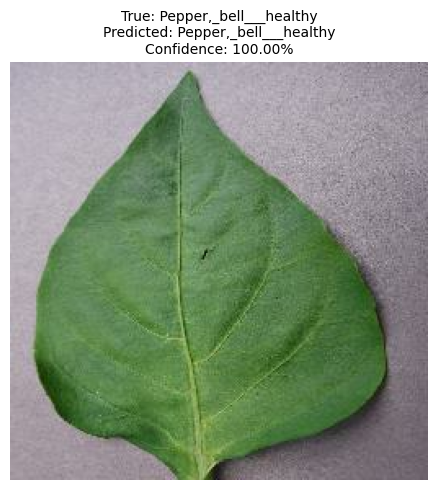


PASS: Test image loaded and prediction obtained.


In [5]:
# ============================================================
# SECTION 1.5: LOAD A PLANTVILLAGE TEST IMAGE
# ============================================================

import kagglehub

# 1. Restore access to the original image dataset
dataset_root = Path(
    kagglehub.dataset_download(
        "aftaabahmedshaik/plantvillage-dataset"
    )
)

PV_COLOUR_DIR = dataset_root / "color"

assert PV_COLOUR_DIR.is_dir(), (
    f"PlantVillage colour folder not found: {PV_COLOUR_DIR}"
)

# 2. Load the original test split
manifest_df = pd.read_csv(SPLIT_MANIFEST_PATH)

test_df = manifest_df.loc[
    manifest_df["split"] == "test"
].copy().reset_index(drop=True)

assert len(test_df) == 8151, "Unexpected test split size."

# 3. Select a reproducible sample without filtering by prediction
sample_row = test_df.sample(
    n=1, random_state=SEED
).iloc[0]

true_class = str(sample_row["plantvillage_class"])
true_index = class_to_index[true_class]

# Resolve the saved filename against the current dataset location
sample_path = (
    PV_COLOUR_DIR
    / true_class
    / Path(sample_row["filepath"]).name
)

assert sample_path.is_file(), (
    f"Selected image not found: {sample_path}"
)


# 4. Match the image loading used during evaluation
def load_leaf_image(filepath):
    image_bytes = tf.io.read_file(str(filepath))

    original = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    original.set_shape([None, None, 3])

    resized = tf.image.resize(
        original,
        IMAGE_SIZE,
        method="bilinear"
    )
    resized = tf.cast(resized, tf.float32)

    return original.numpy(), tf.expand_dims(resized, axis=0)


original_image, image_batch = load_leaf_image(sample_path)

# EfficientNet already contains its rescaling.
# Keep the input in the 0–255 range.

# 5. Obtain the original model prediction
sample_probabilities = model(
    image_batch, training=False
).numpy()[0]

predicted_index = int(np.argmax(sample_probabilities))
predicted_class = class_names[predicted_index]
confidence = float(sample_probabilities[predicted_index])

print("=" * 60)
print("AGROVISION FYP2 - SELECTED TEST IMAGE")
print("=" * 60)

print(f"Filename        : {sample_path.name}")
print(f"True class      : {true_class}")
print(f"Predicted class : {predicted_class}")
print(f"Confidence      : {confidence:.2%}")
print(f"Correct         : {predicted_index == true_index}")
print(f"Model input     : {tuple(image_batch.shape)}")

plt.figure(figsize=(5, 5))
plt.imshow(original_image)
plt.title(
    f"True: {true_class}\n"
    f"Predicted: {predicted_class}\n"
    f"Confidence: {confidence:.2%}",
    fontsize=10
)
plt.axis("off")
plt.tight_layout()
plt.show()

print("\nPASS: Test image loaded and prediction obtained.")

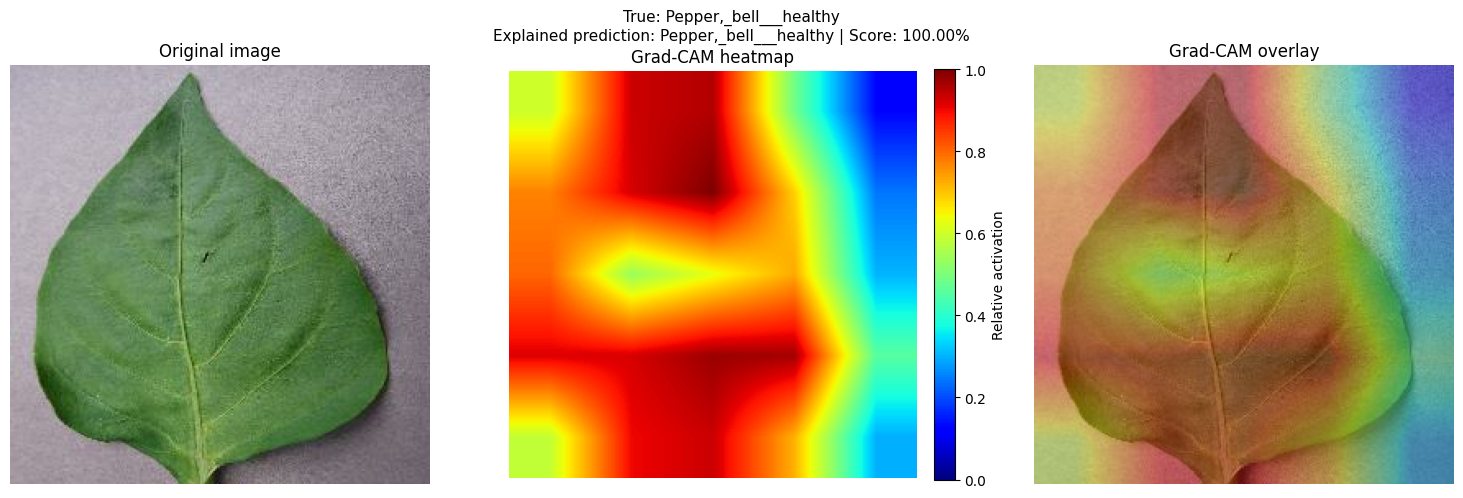

AGROVISION FYP2 - GRAD-CAM OUTPUT
Explained class     : Pepper,_bell___healthy
Target layer        : top_conv
Native heatmap shape: (5, 5)
Heatmap range       : 0.1274 to 1.0000
Maximum |gradient|  : 2.47128606e-02
Positive activation : True
Prediction agreement: VERIFIED


In [6]:
# ============================================================
# SECTION 1.6: GENERATE AND DISPLAY GRAD-CAM
# ============================================================

def generate_gradcam(image_batch, class_index=None):
    """Explain one image, using its predicted class by default."""

    images = tf.cast(tf.convert_to_tensor(image_batch), tf.float32)

    tf.debugging.assert_shapes([
        (images, (1, IMAGE_SIZE[0], IMAGE_SIZE[1], 3))
    ])
    tf.debugging.assert_all_finite(images, "Invalid image values.")

    # 1. Calculate feature maps and the target class score
    with tf.GradientTape() as tape:
        tape.watch(images)

        feature_maps, logits, probabilities = gradcam_forward(images)

        if class_index is None:
            target_index = int(tf.argmax(probabilities[0]).numpy())
        else:
            target_index = int(class_index)

        if not 0 <= target_index < NUM_CLASSES:
            raise ValueError("Class index is outside the model's range.")

        target_score = logits[0, target_index]

    # 2. Differentiate the target score against the feature maps
    gradients = tape.gradient(target_score, feature_maps)

    if gradients is None:
        raise RuntimeError("Target-layer gradients are disconnected.")

    tf.debugging.assert_all_finite(
        feature_maps, "Feature maps contain invalid values."
    )
    tf.debugging.assert_all_finite(
        gradients, "Gradients contain invalid values."
    )

    # 3. Average spatial gradients to obtain one weight per channel
    channel_weights = tf.reduce_mean(
        gradients[0], axis=(0, 1)
    )

    # 4. Combine channels and retain positive contributions
    raw_cam = tf.reduce_sum(
        feature_maps[0] * channel_weights,
        axis=-1
    )
    positive_cam = tf.nn.relu(raw_cam)

    # 5. Normalise safely, including an entirely zero map
    positive_peak = tf.reduce_max(positive_cam)

    heatmap = tf.math.divide_no_nan(
        positive_cam, positive_peak
    )

    tf.debugging.assert_all_finite(
        heatmap, "Heatmap contains invalid values."
    )

    return {
        "heatmap": heatmap.numpy(),
        "probabilities": probabilities.numpy()[0],
        "class_index": target_index,
        "gradient_max_abs": float(
            tf.reduce_max(tf.abs(gradients)).numpy()
        ),
        "has_positive_activation": bool(positive_peak.numpy() > 0)
    }


# 6. Explain the selected image's predicted class
gradcam_result = generate_gradcam(image_batch)

heatmap = gradcam_result["heatmap"]
explained_index = gradcam_result["class_index"]
explained_class = class_names[explained_index]

# Confirm agreement with the original prediction
np.testing.assert_allclose(
    gradcam_result["probabilities"],
    sample_probabilities,
    rtol=1e-5,
    atol=1e-6
)
assert explained_index == predicted_index

# 7. Resize the coarse map to the original image dimensions
heatmap_resized = tf.image.resize(
    heatmap[..., np.newaxis],
    original_image.shape[:2],
    method="bilinear"
).numpy()[..., 0]

heatmap_resized = np.clip(heatmap_resized, 0.0, 1.0)

# 8. Blend the coloured map with the original RGB image
original_float = original_image.astype(np.float32) / 255.0
heatmap_colours = plt.get_cmap("jet")(heatmap_resized)[..., :3]

OVERLAY_ALPHA = 0.4

if gradcam_result["has_positive_activation"]:
    overlay = (
        (1.0 - OVERLAY_ALPHA) * original_float
        + OVERLAY_ALPHA * heatmap_colours
    )
else:
    overlay = original_float.copy()
    print("No positive activation: displaying the original as the overlay.")

# 9. Display the original, heatmap and overlay
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(original_image)
axes[0].set_title("Original image")

heatmap_plot = axes[1].imshow(
    heatmap_resized,
    cmap="jet",
    vmin=0,
    vmax=1
)
axes[1].set_title("Grad-CAM heatmap")

axes[2].imshow(np.clip(overlay, 0.0, 1.0))
axes[2].set_title("Grad-CAM overlay")

for ax in axes:
    ax.axis("off")

fig.colorbar(
    heatmap_plot,
    ax=axes[1],
    fraction=0.046,
    pad=0.04,
    label="Relative activation"
)

fig.suptitle(
    f"True: {true_class}\n"
    f"Explained prediction: {explained_class} | "
    f"Score: {gradcam_result['probabilities'][explained_index]:.2%}",
    fontsize=11
)

fig.tight_layout()
plt.show()

print("=" * 60)
print("AGROVISION FYP2 - GRAD-CAM OUTPUT")
print("=" * 60)
print(f"Explained class     : {explained_class}")
print(f"Target layer        : {TARGET_LAYER_NAME}")
print(f"Native heatmap shape: {heatmap.shape}")
print(f"Heatmap range       : {heatmap.min():.4f} to {heatmap.max():.4f}")
print(f"Maximum |gradient|  : {gradcam_result['gradient_max_abs']:.8e}")
print(f"Positive activation : {gradcam_result['has_positive_activation']}")
print("Prediction agreement: VERIFIED")

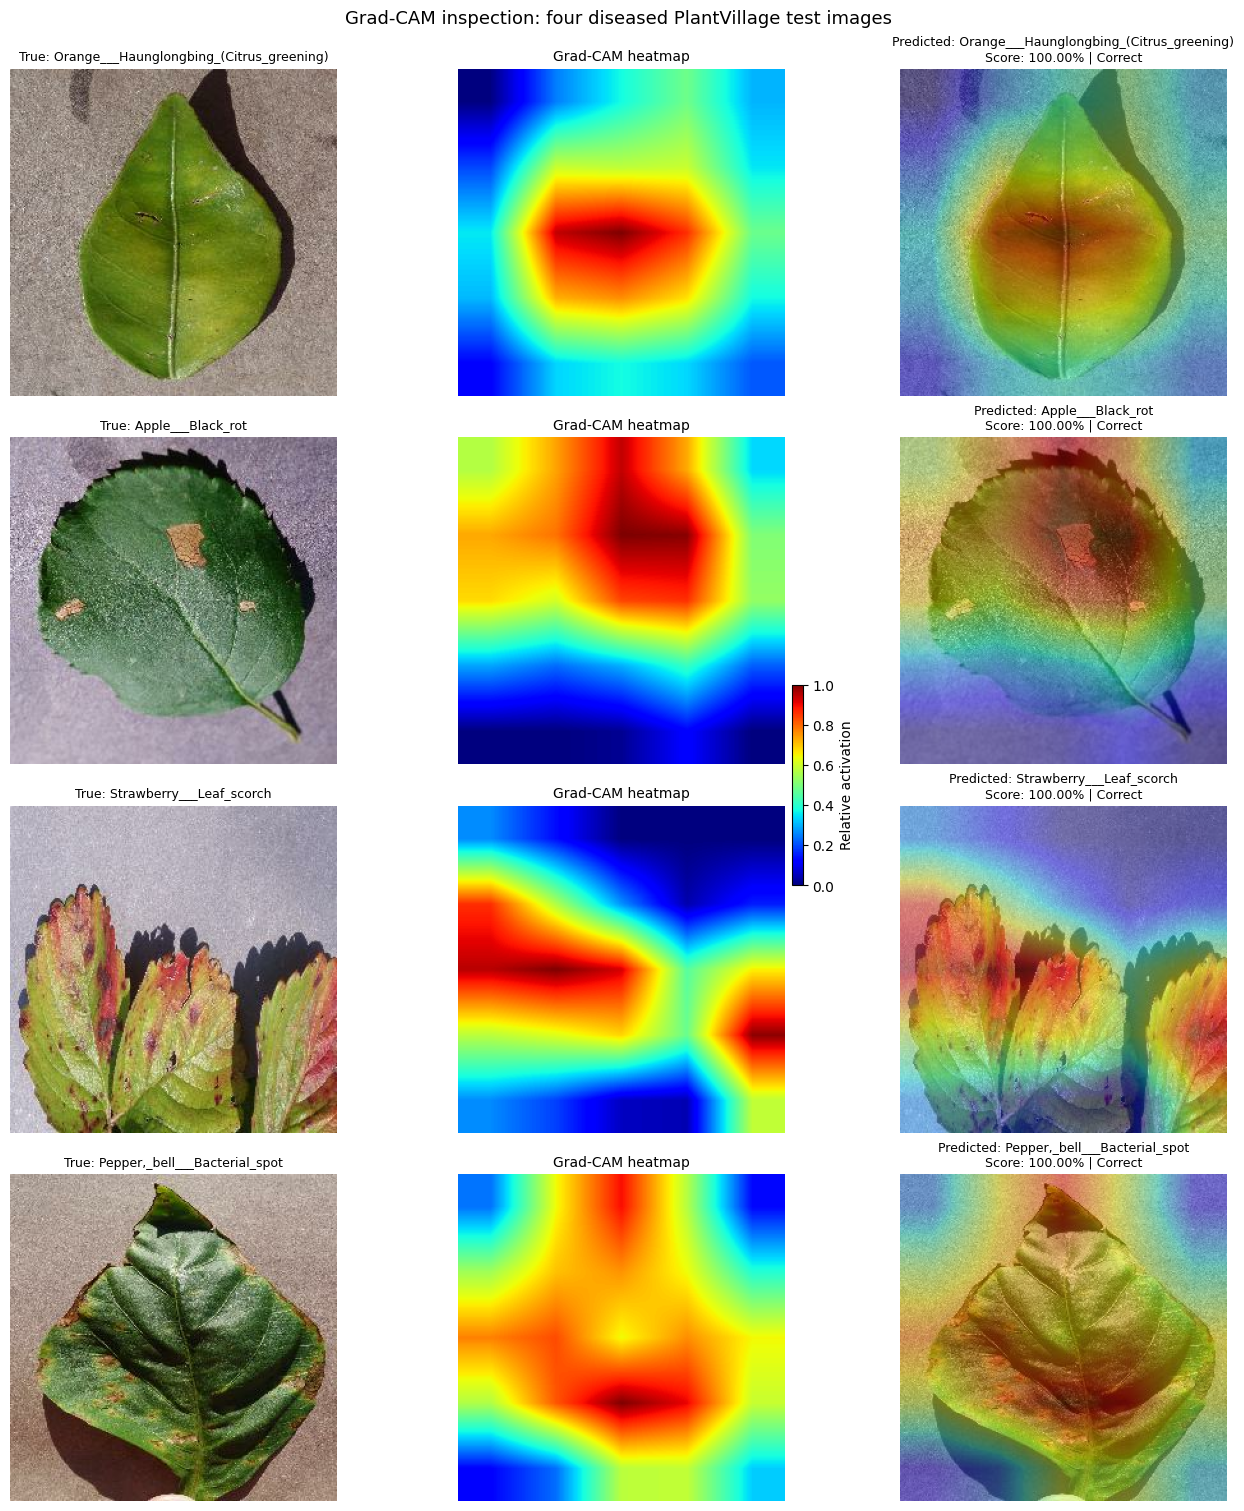

                              true_class                          predicted_class confidence  correct  positive_activation
Orange___Haunglongbing_(Citrus_greening) Orange___Haunglongbing_(Citrus_greening)    100.00%     True                 True
                       Apple___Black_rot                        Apple___Black_rot    100.00%     True                 True
                Strawberry___Leaf_scorch                 Strawberry___Leaf_scorch    100.00%     True                 True
           Pepper,_bell___Bacterial_spot            Pepper,_bell___Bacterial_spot    100.00%     True                 True


In [7]:
# ============================================================
# SECTION 1.7: INSPECT GRAD-CAM ACROSS DISEASED SAMPLES
# ============================================================

# 1. Select diseased test images
diseased_test_df = test_df.loc[
    ~test_df["plantvillage_class"]
    .str.lower()
    .str.endswith("___healthy")
].copy()

diseased_test_df["crop"] = (
    diseased_test_df["plantvillage_class"]
    .str.split("___", n=1)
    .str[0]
)

# Reproducibly select four different crops
available_crops = sorted(diseased_test_df["crop"].unique())

assert len(available_crops) >= 4

rng = np.random.default_rng(SEED)

selected_crops = rng.choice(
    available_crops,
    size=4,
    replace=False
)

selected_cases = [
    diseased_test_df.loc[
        diseased_test_df["crop"] == crop
    ].sample(n=1, random_state=SEED).iloc[0]
    for crop in selected_crops
]


# 2. Reusable resizing and overlay function
def create_gradcam_overlay(original, heatmap, alpha=0.4):
    resized_heatmap = tf.image.resize(
        heatmap[..., np.newaxis],
        original.shape[:2],
        method="bilinear"
    ).numpy()[..., 0]

    resized_heatmap = np.clip(resized_heatmap, 0.0, 1.0)
    original_float = original.astype(np.float32) / 255.0

    if np.max(heatmap) > 0:
        colours = plt.get_cmap("jet")(resized_heatmap)[..., :3]
        overlay = (
            (1.0 - alpha) * original_float
            + alpha * colours
        )
    else:
        overlay = original_float.copy()

    return resized_heatmap, np.clip(overlay, 0.0, 1.0)


# 3. Generate explanations without filtering by correctness
fig, axes = plt.subplots(
    4, 3,
    figsize=(13, 15),
    layout="constrained"
)

case_records = []

for row_index, case in enumerate(selected_cases):
    case_true_class = str(case["plantvillage_class"])

    case_path = (
        PV_COLOUR_DIR
        / case_true_class
        / Path(case["filepath"]).name
    )

    assert case_path.is_file(), f"Image missing: {case_path}"

    case_original, case_batch = load_leaf_image(case_path)
    case_result = generate_gradcam(case_batch)

    case_predicted_index = case_result["class_index"]
    case_predicted_class = class_names[case_predicted_index]
    case_confidence = float(
        case_result["probabilities"][case_predicted_index]
    )

    case_correct = (
        case_predicted_index == class_to_index[case_true_class]
    )

    case_heatmap, case_overlay = create_gradcam_overlay(
        case_original,
        case_result["heatmap"],
        alpha=OVERLAY_ALPHA
    )

    # Keep a record of every selected case
    case_records.append({
        "filename": case_path.name,
        "true_class": case_true_class,
        "predicted_class": case_predicted_class,
        "confidence": case_confidence,
        "correct": case_correct,
        "positive_activation": case_result["has_positive_activation"]
    })

    axes[row_index, 0].imshow(case_original)
    axes[row_index, 0].set_title(
        f"True: {case_true_class}",
        fontsize=9
    )

    heatmap_plot = axes[row_index, 1].imshow(
        case_heatmap,
        cmap="jet",
        vmin=0,
        vmax=1
    )
    axes[row_index, 1].set_title("Grad-CAM heatmap", fontsize=10)

    axes[row_index, 2].imshow(case_overlay)
    axes[row_index, 2].set_title(
        f"Predicted: {case_predicted_class}\n"
        f"Score: {case_confidence:.2%} | "
        f"{'Correct' if case_correct else 'Incorrect'}",
        fontsize=9
    )

    for ax in axes[row_index]:
        ax.axis("off")

fig.colorbar(
    heatmap_plot,
    ax=axes[:, 1].tolist(),
    fraction=0.025,
    pad=0.02,
    label="Relative activation"
)

fig.suptitle(
    "Grad-CAM inspection: four diseased PlantVillage test images",
    fontsize=13
)

plt.show()

# 4. Display the sample-level results
diseased_cases_df = pd.DataFrame(case_records)

print(
    diseased_cases_df[
        [
            "true_class",
            "predicted_class",
            "confidence",
            "correct",
            "positive_activation"
        ]
    ].to_string(
        index=False,
        formatters={"confidence": lambda value: f"{value:.2%}"}
    )
)

In [8]:
# ============================================================
# SECTION 1.8: SELECT CORRECT AND INCORRECT EXTERNAL EXAMPLES
# ============================================================

EXTERNAL_PREDICTION_DIR = (
    MODEL_PATH.parent.parent / "evaluation" / "external"
)

external_configs = {
    "PlantDoc": {
        "inventory": (
            PROJECT_DIR
            / "plantdoc_preparation"
            / "plantdoc_test_inventory.csv"
        ),
        "path_column": "filepath",
        "expected_samples": 236
    },
    "FieldPlant": {
        "inventory": (
            PROJECT_DIR
            / "fieldplant_preparation"
            / "fieldplant_crop_inventory.csv"
        ),
        "path_column": "crop_filepath",
        "expected_samples": 504
    }
}

external_frames = {}
selected_external_frames = []
external_readiness = []

for dataset_name, config in external_configs.items():
    prediction_path = (
        EXTERNAL_PREDICTION_DIR
        / f"{dataset_name}_predictions.npz"
    )

    assert config["inventory"].is_file(), (
        f"Missing inventory: {config['inventory']}"
    )
    assert prediction_path.is_file(), (
        f"Missing predictions: {prediction_path}"
    )

    inventory = pd.read_csv(config["inventory"]).sort_values(
        config["path_column"]
    ).reset_index(drop=True)

    assert len(inventory) == config["expected_samples"]

    with np.load(prediction_path, allow_pickle=False) as saved:
        paths = saved["filepaths"].astype(str)
        true_labels = saved["true_labels"].copy()
        predicted_labels = saved["predicted_labels"].copy()
        probabilities = saved["probabilities"].copy()

        # Preserve the verified relationship between images and labels
        np.testing.assert_array_equal(
            paths,
            inventory[config["path_column"]].to_numpy(dtype=str)
        )
        np.testing.assert_array_equal(
            true_labels,
            inventory["plantvillage_class"]
            .map(class_to_index)
            .to_numpy()
        )
        np.testing.assert_array_equal(
            saved["true_classes"],
            inventory["plantvillage_class"].to_numpy(dtype=str)
        )

    assert probabilities.shape == (
        len(inventory), NUM_CLASSES
    )
    assert np.isfinite(probabilities).all()

    np.testing.assert_array_equal(
        predicted_labels,
        probabilities.argmax(axis=1)
    )

    frame = pd.DataFrame({
        "dataset": dataset_name,
        "filepath": paths,
        "true_index": true_labels,
        "predicted_index": predicted_labels,
        "confidence": probabilities.max(axis=1)
    })

    frame["true_class"] = [
        class_names[int(index)] for index in true_labels
    ]
    frame["predicted_class"] = [
        class_names[int(index)] for index in predicted_labels
    ]
    frame["correct"] = true_labels == predicted_labels
    frame["image_available"] = frame["filepath"].map(
        lambda path: Path(path).is_file()
    )

    external_frames[dataset_name] = frame

    external_readiness.append({
        "dataset": dataset_name,
        "samples": len(frame),
        "represented_classes": frame["true_index"].nunique(),
        "correct": int(frame["correct"].sum()),
        "incorrect": int((~frame["correct"]).sum()),
        "images_available": int(frame["image_available"].sum())
    })

    # Select examples reproducibly within each outcome group
    for correct_status in [True, False]:
        candidates = frame.loc[
            frame["correct"] == correct_status
        ]

        if not candidates.empty:
            selected_external_frames.append(
                candidates.sample(n=1, random_state=SEED)
            )

external_cases_df = pd.concat(
    selected_external_frames,
    ignore_index=True
)

print("=" * 60)
print("AGROVISION FYP2 - EXTERNAL EXAMPLE READINESS")
print("=" * 60)

print("\nDataset summary:")
print(pd.DataFrame(external_readiness).to_string(index=False))

print("\nSelected examples:")
print(
    external_cases_df[
        [
            "dataset",
            "true_class",
            "predicted_class",
            "correct",
            "image_available"
        ]
    ].to_string(index=False)
)

missing_selected = external_cases_df.loc[
    ~external_cases_df["image_available"], "filepath"
]

if not missing_selected.empty:
    print("\nSelected image paths requiring restoration:")
    for path in missing_selected:
        print(path)
else:
    print("\nPASS: Selected external images are accessible.")

AGROVISION FYP2 - EXTERNAL EXAMPLE READINESS

Dataset summary:
   dataset  samples  represented_classes  correct  incorrect  images_available
  PlantDoc      236                   27       64        172                 0
FieldPlant      504                    4      160        344               504

Selected examples:
   dataset                  true_class             predicted_class  correct  image_available
  PlantDoc Tomato___Septoria_leaf_spot Tomato___Septoria_leaf_spot     True            False
  PlantDoc       Potato___Early_blight        Tomato___Late_blight    False            False
FieldPlant      Corn_(maize)___healthy      Corn_(maize)___healthy     True             True
FieldPlant            Tomato___healthy           Soybean___healthy    False             True

Selected image paths requiring restoration:
/content/PlantDoc-Dataset/test/Tomato Septoria leaf spot/2STEM.jpg
/content/PlantDoc-Dataset/test/Potato leaf early blight/early-blight-or-target-spot-alternaria-solani-l

In [9]:
# ============================================================
# SECTION 1.9: RESTORE PLANTDOC IMAGE ACCESS
# ============================================================

import subprocess

PLANTDOC_ROOT = Path("/content/PlantDoc-Dataset")
PLANTDOC_REPOSITORY = (
    "https://github.com/pratikkayal/PlantDoc-Dataset.git"
)

if not PLANTDOC_ROOT.exists():
    print("Restoring PlantDoc images...")

    subprocess.run(
        [
            "git", "clone",
            "--depth", "1",
            PLANTDOC_REPOSITORY,
            str(PLANTDOC_ROOT)
        ],
        check=True
    )
else:
    assert PLANTDOC_ROOT.is_dir(), (
        f"Expected a directory: {PLANTDOC_ROOT}"
    )
    print("PlantDoc directory already exists.")

# Recheck image availability in both external datasets
availability_records = []

for dataset_name, frame in external_frames.items():
    frame["image_available"] = frame["filepath"].map(
        lambda path: Path(path).is_file()
    )

    availability_records.append({
        "dataset": dataset_name,
        "expected_images": len(frame),
        "available_images": int(frame["image_available"].sum())
    })

# Update the existing selection without choosing different images
external_cases_df["image_available"] = (
    external_cases_df["filepath"].map(
        lambda path: Path(path).is_file()
    )
)

print("\n" + "=" * 60)
print("AGROVISION FYP2 - EXTERNAL IMAGE AVAILABILITY")
print("=" * 60)

print(pd.DataFrame(availability_records).to_string(index=False))

print("\nSelected examples:")
print(
    external_cases_df[
        ["dataset", "true_class", "correct", "image_available"]
    ].to_string(index=False)
)

missing_paths = [
    path
    for frame in external_frames.values()
    for path in frame.loc[
        ~frame["image_available"], "filepath"
    ]
]

assert not missing_paths, (
    "External images are still missing:\n"
    + "\n".join(missing_paths[:5])
)

print("\nPASS: All external images are accessible.")
print("Selected examples are ready for Grad-CAM.")

Restoring PlantDoc images...

AGROVISION FYP2 - EXTERNAL IMAGE AVAILABILITY
   dataset  expected_images  available_images
  PlantDoc              236               236
FieldPlant              504               504

Selected examples:
   dataset                  true_class  correct  image_available
  PlantDoc Tomato___Septoria_leaf_spot     True             True
  PlantDoc       Potato___Early_blight    False             True
FieldPlant      Corn_(maize)___healthy     True             True
FieldPlant            Tomato___healthy    False             True

PASS: All external images are accessible.
Selected examples are ready for Grad-CAM.


In [11]:
# ============================================================
# DIAGNOSTIC: CURRENT MODEL VS GRAD-CAM VS SAVED EVALUATION
# ============================================================

# 1. Locate the affected selected example
diagnostic_case = external_cases_df.loc[
    (external_cases_df["dataset"] == "PlantDoc")
    & (~external_cases_df["correct"])
].iloc[0]

diagnostic_path = diagnostic_case["filepath"]
diagnostic_saved = saved_external_predictions["PlantDoc"]

matched = np.flatnonzero(
    diagnostic_saved["filepaths"] == diagnostic_path
)
assert len(matched) == 1

saved_position = int(matched[0])
saved_vector = diagnostic_saved["probabilities"][saved_position]

# 2. Compare both routes using exactly the same single-image input
_, diagnostic_image = load_leaf_image(diagnostic_path)

single_vector = model(
    diagnostic_image, training=False
).numpy()[0]

gradcam_vector = generate_gradcam(
    diagnostic_image
)["probabilities"]

# 3. Reconstruct the original evaluation batch
# Your evaluation notebook used batches of 32 in saved filepath order.
EVALUATION_BATCH_SIZE = 32

batch_start = (
    saved_position // EVALUATION_BATCH_SIZE
) * EVALUATION_BATCH_SIZE

batch_end = min(
    batch_start + EVALUATION_BATCH_SIZE,
    len(diagnostic_saved["filepaths"])
)

batch_paths = diagnostic_saved["filepaths"][batch_start:batch_end]

diagnostic_batch = tf.concat(
    [load_leaf_image(path)[1] for path in batch_paths],
    axis=0
)

position_in_batch = saved_position - batch_start

batch_eager_vector = model(
    diagnostic_batch, training=False
).numpy()[position_in_batch]

batch_predict_vector = model.predict(
    diagnostic_batch,
    batch_size=EVALUATION_BATCH_SIZE,
    verbose=0
)[position_in_batch]

# 4. Report differences before applying any assertion
diagnostic_vectors = {
    "Saved evaluation": saved_vector,
    "Original model: single image": single_vector,
    "Grad-CAM: single image": gradcam_vector,
    "Original model: batch call": batch_eager_vector,
    "Original model: batch predict": batch_predict_vector
}

diagnostic_records = []

for route, vector in diagnostic_vectors.items():
    predicted = int(np.argmax(vector))

    diagnostic_records.append({
        "route": route,
        "predicted_class": class_names[predicted],
        "confidence": float(vector[predicted]),
        "max_diff_vs_saved": float(
            np.max(np.abs(vector - saved_vector))
        ),
        "max_diff_vs_single": float(
            np.max(np.abs(vector - single_vector))
        )
    })

print("Affected image:", Path(diagnostic_path).name)
print(
    "TF32 enabled:",
    tf.config.experimental.tensor_float_32_execution_enabled()
)
print("Reconstructed batch size:", len(batch_paths))

print(
    pd.DataFrame(diagnostic_records).to_string(
        index=False,
        formatters={
            "confidence": lambda value: f"{value:.6%}",
            "max_diff_vs_saved": lambda value: f"{value:.8e}",
            "max_diff_vs_single": lambda value: f"{value:.8e}"
        }
    )
)

# 5. Independently verify the current Grad-CAM route
np.testing.assert_allclose(
    gradcam_vector,
    single_vector,
    rtol=1e-5,
    atol=1e-6,
    err_msg="Current Grad-CAM and original model predictions differ."
)

print("\nPASS: Current Grad-CAM predictions match the original model.")

Affected image: early-blight-or-target-spot-alternaria-solani-lesions-on-a-tomato-AXK6AY.jpg
TF32 enabled: True
Reconstructed batch size: 32
                        route      predicted_class confidence max_diff_vs_saved max_diff_vs_single
             Saved evaluation Tomato___Late_blight 80.307698%    0.00000000e+00     9.17613506e-04
 Original model: single image Tomato___Late_blight 80.215937%    9.17613506e-04     0.00000000e+00
       Grad-CAM: single image Tomato___Late_blight 80.215937%    9.17613506e-04     0.00000000e+00
   Original model: batch call Tomato___Late_blight 80.140901%    1.66797638e-03     7.50362873e-04
Original model: batch predict Tomato___Late_blight 80.175680%    1.32018328e-03     6.33411109e-04

PASS: Current Grad-CAM predictions match the original model.


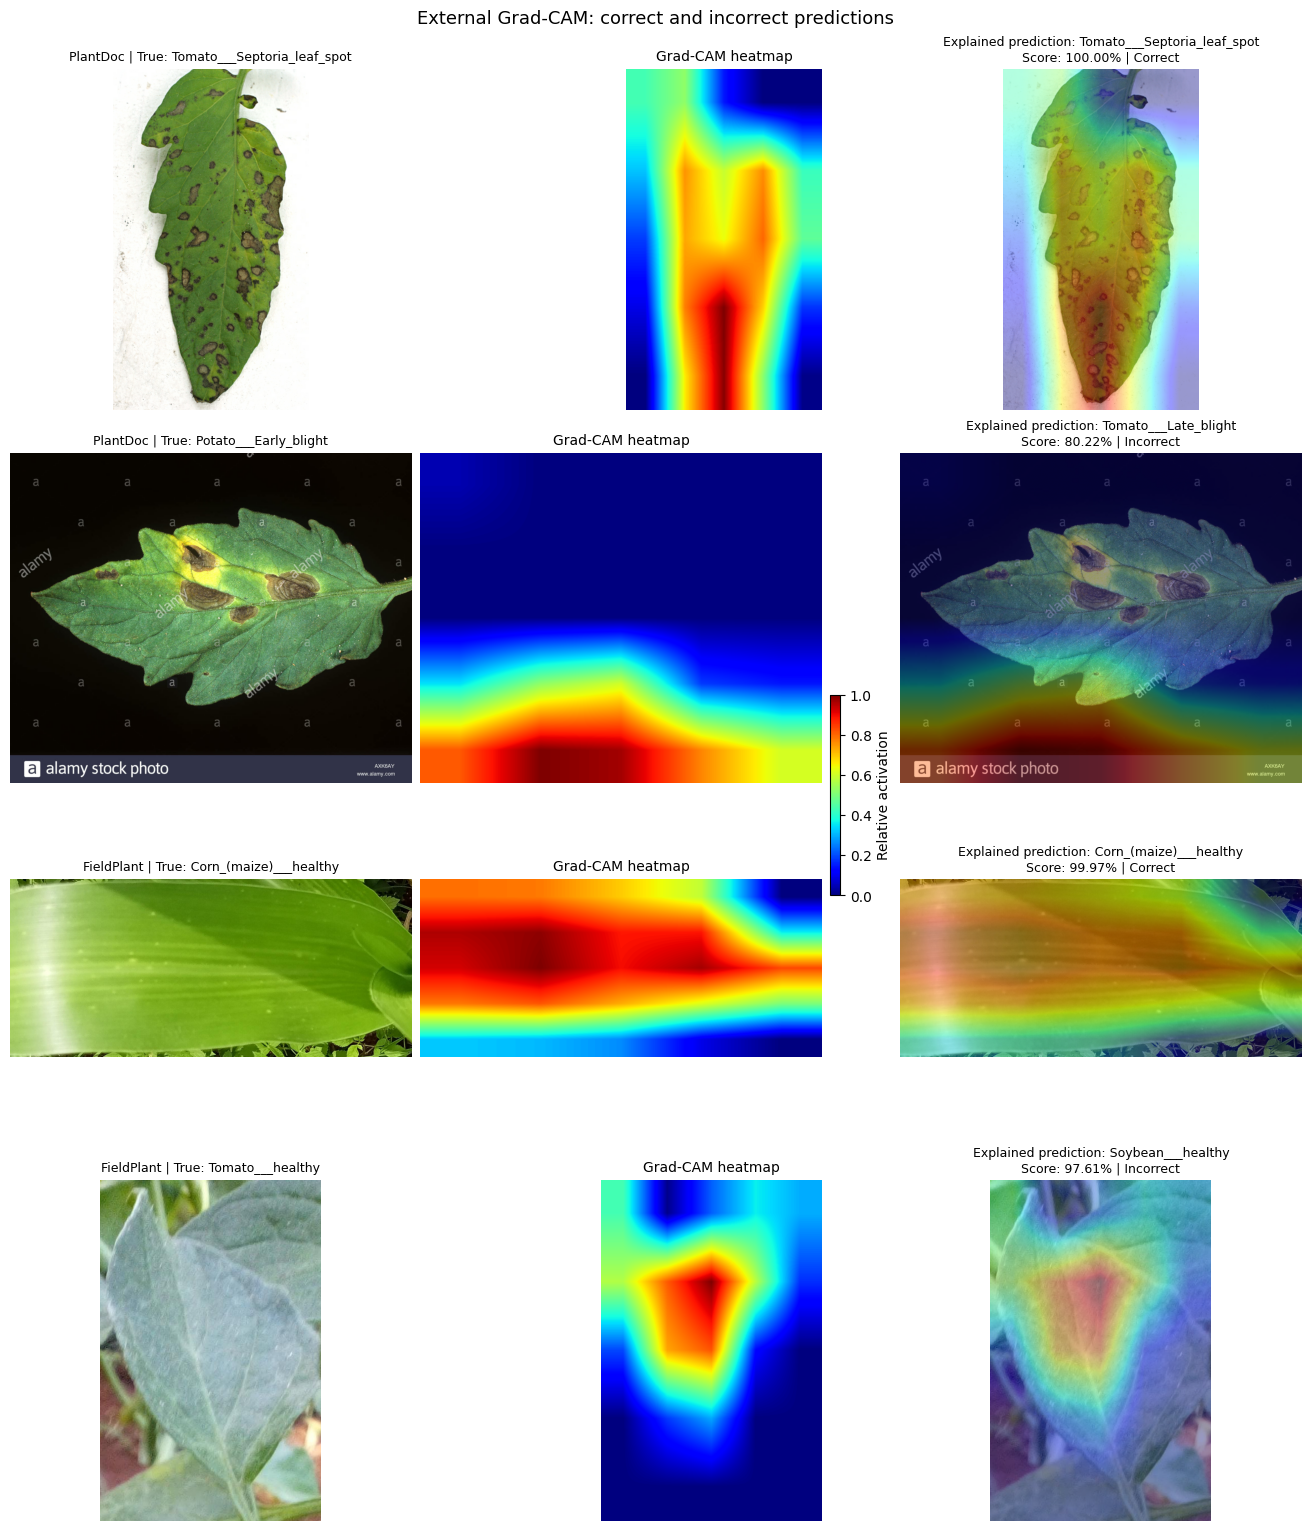

AGROVISION FYP2 - EXTERNAL GRAD-CAM VERIFICATION
   dataset                  true_class             predicted_class confidence  correct  positive_activation max_diff_vs_current max_diff_vs_saved
  PlantDoc Tomato___Septoria_leaf_spot Tomato___Septoria_leaf_spot    100.00%     True                 True            0.00e+00          8.34e-07
  PlantDoc       Potato___Early_blight        Tomato___Late_blight     80.22%    False                 True            0.00e+00          9.18e-04
FieldPlant      Corn_(maize)___healthy      Corn_(maize)___healthy     99.97%     True                 True            0.00e+00          3.40e-06
FieldPlant            Tomato___healthy           Soybean___healthy     97.61%    False                 True            0.00e+00          1.22e-04

PASS: Grad-CAM probabilities match current original-model outputs.
PASS: Selected class labels match the saved evaluation.
Differences from saved probability vectors are reported above.


In [12]:
# ============================================================
# SECTION 1.10: EXTERNAL GRAD-CAM AND PREDICTION VERIFICATION
# ============================================================

# 1. Load saved probability vectors
saved_external_predictions = {}

for dataset_name in external_configs:
    prediction_path = (
        EXTERNAL_PREDICTION_DIR
        / f"{dataset_name}_predictions.npz"
    )

    with np.load(prediction_path, allow_pickle=False) as saved:
        saved_external_predictions[dataset_name] = {
            "filepaths": saved["filepaths"].astype(str),
            "probabilities": saved["probabilities"].copy()
        }

# Reset results so rerunning this cell starts cleanly
external_gradcam_cases = []
external_gradcam_records = []

# 2. Generate and verify each selected explanation
for case in external_cases_df.itertuples(index=False):

    # Load the image using the established preprocessing
    case_original, case_batch = load_leaf_image(case.filepath)

    # Explain the current predicted class
    case_result = generate_gradcam(case_batch)

    # Obtain the original model's prediction on the same input
    current_original_probabilities = model(
        case_batch,
        training=False
    ).numpy()[0]

    # Verify that Grad-CAM preserves current model predictions
    np.testing.assert_allclose(
        case_result["probabilities"],
        current_original_probabilities,
        rtol=1e-5,
        atol=1e-6,
        err_msg=(
            "Grad-CAM differs from the current original model: "
            f"{case.filepath}"
        )
    )

    # Locate the corresponding saved evaluation prediction
    saved_data = saved_external_predictions[case.dataset]

    matched_rows = np.flatnonzero(
        saved_data["filepaths"] == case.filepath
    )

    assert len(matched_rows) == 1, (
        f"Expected one saved prediction for: {case.filepath}"
    )

    saved_probabilities = saved_data["probabilities"][
        matched_rows[0]
    ]

    case_predicted_index = case_result["class_index"]

    # Preserve the correct/incorrect classification used for selection
    assert case_predicted_index == int(case.predicted_index), (
        "Current predicted class differs from the saved evaluation: "
        f"{case.filepath}"
    )

    case_predicted_class = class_names[case_predicted_index]

    case_confidence = float(
        case_result["probabilities"][case_predicted_index]
    )

    case_correct = (
        case_predicted_index == int(case.true_index)
    )

    # Record historical probability differences without hiding them
    max_difference_from_saved = float(
        np.max(
            np.abs(
                case_result["probabilities"]
                - saved_probabilities
            )
        )
    )

    max_difference_from_current = float(
        np.max(
            np.abs(
                case_result["probabilities"]
                - current_original_probabilities
            )
        )
    )

    # Create the resized heatmap and overlay
    case_heatmap, case_overlay = create_gradcam_overlay(
        case_original,
        case_result["heatmap"],
        alpha=OVERLAY_ALPHA
    )

    record = {
        "dataset": case.dataset,
        "filepath": case.filepath,
        "true_class": case.true_class,
        "predicted_class": case_predicted_class,
        "confidence": case_confidence,
        "correct": case_correct,
        "positive_activation": (
            case_result["has_positive_activation"]
        ),
        "max_diff_vs_current": max_difference_from_current,
        "max_diff_vs_saved": max_difference_from_saved
    }

    external_gradcam_records.append(record)

    # Retain images and numerical results for later export
    external_gradcam_cases.append({
        **record,
        "original_image": case_original,
        "native_heatmap": case_result["heatmap"],
        "resized_heatmap": case_heatmap,
        "overlay": case_overlay,
        "probabilities": case_result["probabilities"]
    })

# 3. Display all selected examples
number_of_cases = len(external_gradcam_cases)

assert number_of_cases > 0, "No external examples selected."

fig, axes = plt.subplots(
    number_of_cases,
    3,
    figsize=(13, 3.8 * number_of_cases),
    squeeze=False,
    layout="constrained"
)

for row_index, case in enumerate(external_gradcam_cases):

    axes[row_index, 0].imshow(case["original_image"])
    axes[row_index, 0].set_title(
        f"{case['dataset']} | True: {case['true_class']}",
        fontsize=9
    )

    heatmap_plot = axes[row_index, 1].imshow(
        case["resized_heatmap"],
        cmap="jet",
        vmin=0,
        vmax=1
    )

    axes[row_index, 1].set_title(
        "Grad-CAM heatmap",
        fontsize=10
    )

    axes[row_index, 2].imshow(case["overlay"])
    axes[row_index, 2].set_title(
        f"Explained prediction: {case['predicted_class']}\n"
        f"Score: {case['confidence']:.2%} | "
        f"{'Correct' if case['correct'] else 'Incorrect'}",
        fontsize=9
    )

    for ax in axes[row_index]:
        ax.axis("off")

fig.colorbar(
    heatmap_plot,
    ax=axes[:, 1].tolist(),
    fraction=0.025,
    pad=0.02,
    label="Relative activation"
)

fig.suptitle(
    "External Grad-CAM: correct and incorrect predictions",
    fontsize=13
)

plt.show()

# 4. Display verification results
external_gradcam_summary_df = pd.DataFrame(
    external_gradcam_records
)

print("=" * 60)
print("AGROVISION FYP2 - EXTERNAL GRAD-CAM VERIFICATION")
print("=" * 60)

print(
    external_gradcam_summary_df.drop(
        columns=["filepath"]
    ).to_string(
        index=False,
        formatters={
            "confidence": lambda value: f"{value:.2%}",
            "max_diff_vs_current": lambda value: f"{value:.2e}",
            "max_diff_vs_saved": lambda value: f"{value:.2e}"
        }
    )
)

print(
    "\nPASS: Grad-CAM probabilities match "
    "current original-model outputs."
)
print(
    "PASS: Selected class labels match "
    "the saved evaluation."
)
print(
    "Differences from saved probability vectors "
    "are reported above."
)

In [13]:
# ============================================================
# SECTION 1.11: SAVE EXTERNAL GRAD-CAM RESULTS
# ============================================================

import hashlib
from datetime import datetime
from zoneinfo import ZoneInfo

# 1. Create a separate output folder for this export
export_time = datetime.now(ZoneInfo("Asia/Kuala_Lumpur"))

EXPORT_DIR = (
    PROJECT_DIR
    / "gradcam_explainability"
    / "EfficientNetB0_enhanced_v1"
    / export_time.strftime("%Y%m%d_%H%M%S_%f")
)

EXPORT_DIR.mkdir(parents=True, exist_ok=False)

# 2. Save the comparison figure from Cell 10
comparison_path = EXPORT_DIR / "external_gradcam_comparison.png"

fig.savefig(
    comparison_path,
    dpi=200,
    bbox_inches="tight"
)

# 3. Save the summary table
summary_path = EXPORT_DIR / "external_gradcam_summary.csv"

external_gradcam_summary_df.to_csv(
    summary_path,
    index=False,
    float_format="%.10g"
)

# 4. Save each example's images and numerical arrays
for case_number, case in enumerate(
    external_gradcam_cases,
    start=1
):
    outcome = "correct" if case["correct"] else "incorrect"

    case_dir = EXPORT_DIR / (
        f"{case_number:02d}_{case['dataset']}_{outcome}"
    )
    case_dir.mkdir()

    plt.imsave(
        case_dir / "original.png",
        case["original_image"]
    )

    plt.imsave(
        case_dir / "heatmap.png",
        case["resized_heatmap"],
        cmap="jet",
        vmin=0,
        vmax=1
    )

    plt.imsave(
        case_dir / "overlay.png",
        case["overlay"]
    )

    saved_data = saved_external_predictions[case["dataset"]]

    matched_rows = np.flatnonzero(
        saved_data["filepaths"] == case["filepath"]
    )
    assert len(matched_rows) == 1

    archived_probabilities = saved_data["probabilities"][
        matched_rows[0]
    ]

    np.savez_compressed(
        case_dir / "numerical_results.npz",
        native_heatmap=case["native_heatmap"],
        resized_heatmap=case["resized_heatmap"],
        current_probabilities=case["probabilities"],
        archived_probabilities=archived_probabilities,
        true_index=class_to_index[case["true_class"]],
        explained_index=class_to_index[case["predicted_class"]]
    )

    with open(
        case_dir / "case_metadata.json",
        "w",
        encoding="utf-8"
    ) as file:
        json.dump(
            external_gradcam_records[case_number - 1],
            file,
            indent=2,
            ensure_ascii=False,
            allow_nan=False
        )

# 5. Record the checkpoint identity
checkpoint_hasher = hashlib.sha256()

with open(MODEL_PATH, "rb") as file:
    for chunk in iter(lambda: file.read(1024 * 1024), b""):
        checkpoint_hasher.update(chunk)

# 6. Save the explanation configuration
export_metadata = {
    "created_at": export_time.isoformat(),
    "model_name": model.name,
    "checkpoint_path": str(MODEL_PATH),
    "checkpoint_sha256": checkpoint_hasher.hexdigest(),
    "target_layer": TARGET_LAYER_NAME,
    "native_heatmap_size": [5, 5],
    "image_size": list(IMAGE_SIZE),
    "colour_mode": "RGB",
    "input_pixel_range": [0, 255],
    "resize_method": "bilinear",
    "preprocessing": "Use the model's built-in EfficientNet preprocessing",
    "inference_training_argument": False,
    "gradient_target": "Predicted-class score before softmax",
    "heatmap_processing": (
        "Spatially averaged gradients; channel-weighted sum; "
        "ReLU; divide by the positive maximum"
    ),
    "overlay_colormap": "jet",
    "overlay_alpha": OVERLAY_ALPHA,
    "selection_seed": SEED,
    "selection_method": (
        "One randomly selected correct and one incorrect example "
        "per external dataset, based on archived predictions"
    ),
    "number_of_examples": len(external_gradcam_cases),
    "assessment": "Qualitative visual inspection",
    "tensorflow_version": tf.__version__,
    "numpy_version": np.__version__,
    "python_version": sys.version.split()[0],
    "tf32_enabled": (
        tf.config.experimental.tensor_float_32_execution_enabled()
    ),
    "class_to_index": class_to_index,
    "historical_probability_differences": (
        "Recorded in the summary; their cause remains unresolved"
    ),
    "annotation_review_note": (
        "The selected PlantDoc potato early blight example has "
        "'tomato' in its filename. Its reference label remains unchanged."
    )
}

with open(
    EXPORT_DIR / "gradcam_configuration.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        export_metadata,
        file,
        indent=2,
        ensure_ascii=False,
        allow_nan=False
    )

print("=" * 60)
print("AGROVISION FYP2 - GRAD-CAM RESULTS SAVED")
print("=" * 60)

print(f"Examples saved   : {len(external_gradcam_cases)}")
print("Comparison figure: external_gradcam_comparison.png")
print("Summary table    : external_gradcam_summary.csv")
print("Configuration    : gradcam_configuration.json")
print(f"\nOutput folder:\n{EXPORT_DIR}")

AGROVISION FYP2 - GRAD-CAM RESULTS SAVED
Examples saved   : 4
Comparison figure: external_gradcam_comparison.png
Summary table    : external_gradcam_summary.csv
Configuration    : gradcam_configuration.json

Output folder:
/content/drive/MyDrive/AgroVision_FYP2/gradcam_explainability/EfficientNetB0_enhanced_v1/20261119_003356_747247


In [14]:
# ============================================================
# SECTION 1.12: CREATE THE WEB INTEGRATION MODULE
# ============================================================

import shutil
import textwrap
import py_compile
from importlib.metadata import version

INTEGRATION_DIR = EXPORT_DIR / "web_integration"
INTEGRATION_DIR.mkdir(parents=True, exist_ok=True)

module_code = r'''
"""Grad-CAM inference for the trained AgroVision EfficientNetB0 model."""

import json
from pathlib import Path

import numpy as np
import tensorflow as tf
from matplotlib import colormaps


class AgroVisionGradCAM:
    """Load once, then explain uploaded image bytes or image files."""

    def __init__(
        self,
        model_path=None,
        class_mapping_path=None,
        target_layer="top_conv",
        overlay_alpha=0.4
    ):
        module_dir = Path(__file__).resolve().parent

        if model_path is None:
            model_path = module_dir / "model.keras"

        if class_mapping_path is None:
            class_mapping_path = module_dir / "class_to_index.json"

        self.model_path = Path(model_path)
        self.class_mapping_path = Path(class_mapping_path)

        if not 0 <= overlay_alpha <= 1:
            raise ValueError("overlay_alpha must be between 0 and 1.")

        self.overlay_alpha = float(overlay_alpha)
        self.target_layer = target_layer

        with self.class_mapping_path.open(encoding="utf-8") as file:
            self.class_to_index = json.load(file)

        self.num_classes = len(self.class_to_index)

        if self.num_classes != 38:
            raise ValueError("Expected the trained 38-class mapping.")

        if set(self.class_to_index.values()) != set(range(38)):
            raise ValueError("Class indices must cover 0 to 37.")

        self.class_names = [
            name
            for name, index in sorted(
                self.class_to_index.items(),
                key=lambda item: item[1]
            )
        ]

        self.model = tf.keras.models.load_model(
            self.model_path,
            compile=False,
            safe_mode=True
        )

        if self.model.input_shape != (None, 160, 160, 3):
            raise ValueError("Unexpected model input shape.")

        if self.model.output_shape != (None, self.num_classes):
            raise ValueError("Model outputs do not match the class mapping.")

        self.image_size = tuple(self.model.input_shape[1:3])
        backbone = self.model.get_layer("efficientnetb0")

        self.prefix_model = tf.keras.Model(
            inputs=self.model.input,
            outputs=self.model.get_layer(
                "efficientnet_input_passthrough"
            ).output
        )

        self.feature_model = tf.keras.Model(
            inputs=backbone.input,
            outputs=[
                backbone.get_layer(self.target_layer).output,
                backbone.output
            ]
        )

        self.pooling = self.model.get_layer("global_average_pooling")
        self.dropout = self.model.get_layer("classifier_dropout")
        self.classifier = self.model.get_layer("disease_predictions")

        if self.classifier.get_config()["activation"] != "softmax":
            raise ValueError("Expected a softmax classification layer.")

    def _load_image(self, image_source):
        if isinstance(image_source, (str, Path)):
            image_bytes = tf.io.read_file(str(image_source))
        elif isinstance(image_source, (bytes, bytearray)):
            image_bytes = tf.convert_to_tensor(
                bytes(image_source),
                dtype=tf.string
            )
        else:
            raise TypeError("Provide an image filepath or image bytes.")

        original = tf.io.decode_image(
            image_bytes,
            channels=3,
            expand_animations=False
        )
        original.set_shape([None, None, 3])

        resized = tf.image.resize(
            original,
            self.image_size,
            method="bilinear",
            antialias=False
        )

        # The checkpoint includes EfficientNet preprocessing.
        images = tf.expand_dims(
            tf.cast(resized, tf.float32),
            axis=0
        )

        tf.debugging.assert_all_finite(images, "Invalid image values.")

        return original.numpy(), images

    def _forward(self, images):
        x = self.prefix_model(images, training=False)

        feature_maps, backbone_output = self.feature_model(
            x,
            training=False
        )

        x = self.pooling(backbone_output)
        x = self.dropout(x, training=False)
        x = tf.cast(x, self.classifier.compute_dtype)

        logits = tf.linalg.matmul(
            x,
            tf.cast(self.classifier.kernel, x.dtype)
        )

        if self.classifier.use_bias:
            logits = tf.nn.bias_add(
                logits,
                tf.cast(self.classifier.bias, x.dtype)
            )

        probabilities = self.classifier(x)

        return feature_maps, logits, probabilities

    def explain(self, image_source):
        """Return the prediction, heatmaps, overlay and overlay PNG bytes."""

        original, images = self._load_image(image_source)

        with tf.GradientTape() as tape:
            tape.watch(images)

            feature_maps, logits, probabilities = self._forward(images)

            predicted_index = int(
                tf.argmax(probabilities[0]).numpy()
            )
            target_score = logits[0, predicted_index]

        gradients = tape.gradient(target_score, feature_maps)

        if gradients is None:
            raise RuntimeError("Grad-CAM gradients are disconnected.")

        tf.debugging.assert_all_finite(
            feature_maps, "Invalid feature maps."
        )
        tf.debugging.assert_all_finite(
            gradients, "Invalid gradients."
        )
        tf.debugging.assert_all_finite(
            probabilities, "Invalid prediction probabilities."
        )

        channel_weights = tf.reduce_mean(
            gradients[0],
            axis=(0, 1)
        )

        raw_cam = tf.reduce_sum(
            feature_maps[0] * channel_weights,
            axis=-1
        )

        positive_cam = tf.nn.relu(raw_cam)
        positive_peak = tf.reduce_max(positive_cam)

        native_heatmap = tf.math.divide_no_nan(
            positive_cam,
            positive_peak
        ).numpy()

        resized_heatmap = tf.image.resize(
            native_heatmap[..., np.newaxis],
            original.shape[:2],
            method="bilinear",
            antialias=False
        ).numpy()[..., 0]

        resized_heatmap = np.clip(resized_heatmap, 0.0, 1.0)

        has_positive_activation = bool(positive_peak.numpy() > 0)
        original_float = original.astype(np.float32) / 255.0

        if has_positive_activation:
            colours = colormaps["jet"](resized_heatmap)[..., :3]

            overlay = (
                (1.0 - self.overlay_alpha) * original_float
                + self.overlay_alpha * colours
            )
        else:
            overlay = original_float.copy()

        overlay = np.clip(overlay, 0.0, 1.0)
        overlay_uint8 = np.rint(overlay * 255.0).astype(np.uint8)

        probability_vector = probabilities.numpy()[0]

        return {
            "predicted_index": predicted_index,
            "predicted_class": self.class_names[predicted_index],
            "confidence": float(probability_vector[predicted_index]),
            "probabilities": probability_vector,
            "target_layer": self.target_layer,
            "has_positive_activation": has_positive_activation,
            "gradient_max_abs": float(
                tf.reduce_max(tf.abs(gradients)).numpy()
            ),
            "original_image": original,
            "native_heatmap": native_heatmap,
            "resized_heatmap": resized_heatmap,
            "overlay": overlay,
            "overlay_uint8": overlay_uint8,
            "overlay_png": tf.io.encode_png(overlay_uint8).numpy()
        }
'''

# 1. Write the standalone Python module
module_path = INTEGRATION_DIR / "gradcam.py"

module_path.write_text(
    textwrap.dedent(module_code).lstrip(),
    encoding="utf-8"
)

# 2. Copy the checkpoint and its original class mapping
shutil.copy2(
    MODEL_PATH,
    INTEGRATION_DIR / "model.keras"
)

shutil.copy2(
    CLASS_MAPPING_PATH,
    INTEGRATION_DIR / "class_to_index.json"
)

# 3. Include the configuration recorded during export
shutil.copy2(
    EXPORT_DIR / "gradcam_configuration.json",
    INTEGRATION_DIR / "gradcam_configuration.json"
)

# 4. Record the package versions used in this runtime
requirements = (
    f"tensorflow=={tf.__version__}\n"
    f"numpy=={np.__version__}\n"
    f"matplotlib=={version('matplotlib')}\n"
)

(INTEGRATION_DIR / "requirements.txt").write_text(
    requirements,
    encoding="utf-8"
)

# 5. Add usage instructions
usage_text = """
AgroVision Grad-CAM integration

Python version used during development: {python_version}

Install dependencies:
    pip install -r requirements.txt

Keep gradcam.py, model.keras and class_to_index.json together.

Create one instance when the application starts:
    from gradcam import AgroVisionGradCAM
    explainer = AgroVisionGradCAM()

Explain an image file:
    result = explainer.explain("leaf.jpg")

Explain uploaded image bytes in Flask:
    uploaded_file = request.files["image"]
    result = explainer.explain(uploaded_file.read())

Useful result fields:
    result["predicted_class"]
    result["confidence"]         # Value between 0 and 1
    result["overlay_png"]        # PNG bytes for display or saving
    result["has_positive_activation"]

The result also includes NumPy arrays. Select or convert the fields
required by your Flask response before serialising them to JSON.

If has_positive_activation is False, the overlay contains the original
image and the heatmap contains zeros.

Grad-CAM provides a coarse visual explanation of the predicted class.
It does not provide disease segmentation or confirm prediction correctness.

The configuration file records the checkpoint hash, preprocessing
and explanation settings.
""".format(
    python_version=sys.version.split()[0]
)

(INTEGRATION_DIR / "USAGE.txt").write_text(
    textwrap.dedent(usage_text).lstrip(),
    encoding="utf-8"
)

# 6. Check Python syntax
py_compile.compile(
    str(module_path),
    doraise=True
)

print("=" * 60)
print("AGROVISION FYP2 - INTEGRATION FILES CREATED")
print("=" * 60)

for path in sorted(INTEGRATION_DIR.iterdir()):
    if path.is_file():
        print(f"{path.name}: {path.stat().st_size / 1024:.1f} KiB")

print("\nPython syntax: VERIFIED")
print("Numerical verification: Next step")
print(f"\nIntegration folder:\n{INTEGRATION_DIR}")

AGROVISION FYP2 - INTEGRATION FILES CREATED
USAGE.txt: 1.2 KiB
class_to_index.json: 1.4 KiB
gradcam.py: 7.5 KiB
gradcam_configuration.json: 2.8 KiB
model.keras: 41703.8 KiB
requirements.txt: 0.0 KiB

Python syntax: VERIFIED
Numerical verification: Next step

Integration folder:
/content/drive/MyDrive/AgroVision_FYP2/gradcam_explainability/EfficientNetB0_enhanced_v1/20261119_003356_747247/web_integration


In [15]:
# ============================================================
# SECTION 1.13: VERIFY AND PACKAGE THE INTEGRATION MODULE
# ============================================================

import hashlib
import importlib.util
import zipfile
from datetime import datetime
from zoneinfo import ZoneInfo

print("=" * 60)
print("AGROVISION FYP2 - INTEGRATION VERIFICATION")
print("=" * 60)

# 1. Check the dependency file
requirements_path = INTEGRATION_DIR / "requirements.txt"
requirements_text = requirements_path.read_text(encoding="utf-8")

assert requirements_text.strip(), "The requirements file is empty."

print(f"\nRequirements size: {requirements_path.stat().st_size} bytes")
print(requirements_text)

# 2. Verify the copied checkpoint against the recorded hash
with (
    INTEGRATION_DIR / "gradcam_configuration.json"
).open(encoding="utf-8") as file:
    integration_config = json.load(file)

copied_checkpoint = INTEGRATION_DIR / "model.keras"
copied_hasher = hashlib.sha256()

with copied_checkpoint.open("rb") as file:
    for chunk in iter(lambda: file.read(1024 * 1024), b""):
        copied_hasher.update(chunk)

copied_checkpoint_hash = copied_hasher.hexdigest()

assert copied_checkpoint_hash == integration_config["checkpoint_sha256"], (
    "The copied checkpoint differs from the recorded checkpoint."
)

print("Checkpoint SHA-256: VERIFIED")

# 3. Import the exported module directly from its file
module_path = INTEGRATION_DIR / "gradcam.py"

spec = importlib.util.spec_from_file_location(
    "agrovision_gradcam_export",
    module_path
)

assert spec is not None and spec.loader is not None

integration_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(integration_module)

# Default paths must resolve to the files beside gradcam.py
verification_explainer = integration_module.AgroVisionGradCAM()

assert verification_explainer.model_path.resolve() == (
    INTEGRATION_DIR / "model.keras"
).resolve()

assert verification_explainer.class_to_index == class_to_index

print("Module import and class mapping: VERIFIED")

# 4. Compare exported results against the notebook results
module_verification_records = []

for case in external_gradcam_cases:
    exported_result = verification_explainer.explain(
        case["filepath"]
    )

    assert exported_result["predicted_class"] == case["predicted_class"]
    assert (
        exported_result["has_positive_activation"]
        == case["positive_activation"]
    )

    np.testing.assert_allclose(
        exported_result["probabilities"],
        case["probabilities"],
        rtol=1e-5,
        atol=1e-6,
        err_msg=f"Exported probabilities differ: {case['filepath']}"
    )

    np.testing.assert_allclose(
        exported_result["native_heatmap"],
        case["native_heatmap"],
        rtol=1e-5,
        atol=1e-6,
        err_msg=f"Exported heatmap differs: {case['filepath']}"
    )

    np.testing.assert_allclose(
        exported_result["overlay"],
        case["overlay"],
        rtol=1e-5,
        atol=1e-6,
        err_msg=f"Exported overlay differs: {case['filepath']}"
    )

    # Verify that the PNG bytes decode to the intended overlay
    decoded_overlay = tf.io.decode_png(
        exported_result["overlay_png"],
        channels=3
    ).numpy()

    np.testing.assert_array_equal(
        decoded_overlay,
        exported_result["overlay_uint8"]
    )

    module_verification_records.append({
        "dataset": case["dataset"],
        "filepath": case["filepath"],
        "predicted_class": exported_result["predicted_class"],
        "max_probability_difference": float(
            np.max(
                np.abs(
                    exported_result["probabilities"]
                    - case["probabilities"]
                )
            )
        ),
        "max_heatmap_difference": float(
            np.max(
                np.abs(
                    exported_result["native_heatmap"]
                    - case["native_heatmap"]
                )
            )
        ),
        "max_overlay_difference": float(
            np.max(
                np.abs(
                    exported_result["overlay"]
                    - case["overlay"]
                )
            )
        ),
        "png_verified": True
    })

# 5. Test the image-bytes input used for Flask uploads
bytes_test_case = external_gradcam_cases[0]

uploaded_image_bytes = Path(
    bytes_test_case["filepath"]
).read_bytes()

bytes_result = verification_explainer.explain(
    uploaded_image_bytes
)

assert bytes_result["predicted_class"] == (
    bytes_test_case["predicted_class"]
)

np.testing.assert_allclose(
    bytes_result["probabilities"],
    bytes_test_case["probabilities"],
    rtol=1e-5,
    atol=1e-6
)

np.testing.assert_allclose(
    bytes_result["native_heatmap"],
    bytes_test_case["native_heatmap"],
    rtol=1e-5,
    atol=1e-6
)

print("Uploaded image bytes: VERIFIED")

# 6. Save the numerical verification results
module_verification_df = pd.DataFrame(
    module_verification_records
)

module_verification_df.to_csv(
    INTEGRATION_DIR / "module_verification.csv",
    index=False,
    float_format="%.10g"
)

verification_metadata = {
    "status": "passed",
    "verified_at": datetime.now(
        ZoneInfo("Asia/Kuala_Lumpur")
    ).isoformat(),
    "scope": (
        "Export consistency on four selected external examples; "
        "image-bytes input checked on one example"
    ),
    "examples_checked": len(module_verification_records),
    "checkpoint_sha256": copied_checkpoint_hash,
    "class_mapping_verified": True,
    "probabilities_verified": True,
    "native_heatmaps_verified": True,
    "overlays_verified": True,
    "png_encoding_verified": True,
    "uploaded_bytes_verified": True,
    "tensorflow_version": tf.__version__,
    "numpy_version": np.__version__,
    "tf32_enabled": (
        tf.config.experimental.tensor_float_32_execution_enabled()
    )
}

with (
    INTEGRATION_DIR / "module_verification.json"
).open("w", encoding="utf-8") as file:
    json.dump(
        verification_metadata,
        file,
        indent=2,
        allow_nan=False
    )

# 7. Package the integration files after verification passes
ZIP_PATH = EXPORT_DIR / "AgroVision_GradCAM_Integration.zip"

with zipfile.ZipFile(
    ZIP_PATH,
    mode="w",
    compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in sorted(INTEGRATION_DIR.iterdir()):
        if path.is_file():
            archive.write(path, arcname=path.name)

# 8. Display the final results
print("\nNumerical comparison:")
print(
    module_verification_df.drop(
        columns=["filepath"]
    ).to_string(
        index=False,
        formatters={
            "max_probability_difference": lambda value: f"{value:.2e}",
            "max_heatmap_difference": lambda value: f"{value:.2e}",
            "max_overlay_difference": lambda value: f"{value:.2e}"
        }
    )
)

print("\nPASS: Standalone module verification completed.")
print(f"ZIP size: {ZIP_PATH.stat().st_size / 1024**2:.2f} MiB")
print(f"\nIntegration ZIP:\n{ZIP_PATH}")

AGROVISION FYP2 - INTEGRATION VERIFICATION

Requirements size: 51 bytes
tensorflow==2.21.0
numpy==2.4.6
matplotlib==3.10.0

Checkpoint SHA-256: VERIFIED
Module import and class mapping: VERIFIED
Uploaded image bytes: VERIFIED

Numerical comparison:
   dataset             predicted_class max_probability_difference max_heatmap_difference max_overlay_difference  png_verified
  PlantDoc Tomato___Septoria_leaf_spot                   0.00e+00               0.00e+00               0.00e+00          True
  PlantDoc        Tomato___Late_blight                   0.00e+00               0.00e+00               0.00e+00          True
FieldPlant      Corn_(maize)___healthy                   0.00e+00               0.00e+00               0.00e+00          True
FieldPlant           Soybean___healthy                   0.00e+00               0.00e+00               0.00e+00          True

PASS: Standalone module verification completed.
ZIP size: 37.09 MiB

Integration ZIP:
/content/drive/MyDrive/AgroVision_